# Rank1 on the IR 2 testbed: analysis

Tables and figures from the saved outputs of the testbed runs (T0 to T4), scored with the testbed's own functions.

In [1]:
import sys, json, statistics, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FormatStrFormatter, NullFormatter

OUT = Path("rank1_testbed_outputs")       # extracted archive of the testbed run
TESTBED = Path("ir2-testbed")
FIG, TAB = Path("figures"), Path("tables")
if not TESTBED.exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/kimgerdes/ir2-testbed", str(TESTBED)], check=True)
sys.path.insert(0, str(TESTBED.resolve()))
import testbed as tb

FIG.mkdir(exist_ok=True)
TAB.mkdir(exist_ok=True)
SIZES = ["0.5b", "1.5b", "3b"]
RANK1 = [f"T{m}-{s}" for m in (1, 2) for s in SIZES] + ["T3-3b", "T4-3b"]
TAGS = ["T0"] + RANK1
NAMES = {"scifact": "SciFact", "nfcorpus": "NFCorpus", "arguana": "ArguAna"}
LABEL = {"BM25": "BM25", "T0": "T0 cross-encoder", **{f"T1-{s}": f"Rank1-{s.upper()} reasoning" for s in SIZES},
         **{f"T2-{s}": f"Rank1-{s.upper()} no reasoning" for s in SIZES},
         "T3-3b": "Rank1-3B reasoning, authors' prompt", "T4-3b": "Rank1-3B no reasoning, authors' prompt"}

In [2]:
def read_jsonl(path):
    recs = {}
    for line in open(path):
        r = json.loads(line)
        recs[(r["qid"], r["did"])] = r
    return recs


pairs, runs, ndcg, seconds = {}, {}, {}, {}
queries, qrels, texts = {}, {}, {}
for name in tb.DATASETS:
    corpus, queries[name], qrels[name] = tb.load(name)
    texts[name] = dict(zip(corpus, tb.doc_texts(corpus)))
    for tag in TAGS:
        pairs[(tag, name)] = read_jsonl(OUT / "work" / "results" / tag / f"{name}.jsonl")
        runs[(tag, name)] = json.load(open(OUT / "work" / "runs" / tag / f"{name}.json"))
        qids, nd, _ = tb.score_run(runs[(tag, name)], name)
        ndcg[(tag, name)] = dict(zip(qids, nd))
        if tag != "T0":
            t = [json.loads(l) for l in open(OUT / "work" / "results" / tag / f"{name}.timing.jsonl")]
            seconds[(tag, name)] = sum(x["seconds"] for x in t) / sum(x["pairs"] for x in t)
    st = tb.stored()[name]                     # bm25 per query, as stored by the testbed
    ndcg[("BM25", name)] = dict(zip(st["qids"], st["bm25"]["ndcg10"]))
    print(f"{name}: {len(queries[name])} queries, {len(pairs[('T0', name)])} pairs per run")

# per-query nDCG@10 of every run, the base of every test below
with open(TAB / "per_query_ndcg10.csv", "w") as f:
    f.write("dataset,query," + ",".join(["BM25"] + TAGS) + "\n")
    for name in tb.DATASETS:
        for q in queries[name]:
            f.write(f"{name},{q}," + ",".join(f"{ndcg[(t, name)][q]:.4f}" for t in ["BM25"] + TAGS) + "\n")

scifact: 300 queries, 6000 pairs per run


nfcorpus: 323 queries, 6460 pairs per run


arguana: 1406 queries, 28120 pairs per run


In [3]:
def arr(tag, name):
    return np.array([ndcg[(tag, name)][q] for q in queries[name]])


def cmp(a_tag, b_tag, name):
    v = tb.compare(arr(a_tag, name), arr(b_tag, name))
    p = "< 0.001" if v["p"] < 0.001 else f"{v['p']:.3f}"
    return f"{v['delta']:+.3f} [{v['ci95'][0]:+.3f}, {v['ci95'][1]:+.3f}]", p


def tokens(tag, name):
    return [r["ntok"] for r in pairs[(tag, name)].values()]


def write(md, file):
    (TAB / file).write_text(md + "\n")
    print(md)


# effectiveness and cost of every run
rows = ["| Dataset | Run | nDCG@10 | Δ vs T0 [95 % CI] | p | tokens/pair | s/pair (T4) |", "|---|---|:-:|:-:|:-:|:-:|:-:|"]
for name in tb.DATASETS:
    for tag in ["BM25"] + TAGS:
        d, p = cmp(tag, "T0", name) if tag != "T0" else ("", "")
        tok = f"{statistics.mean(tokens(tag, name)):.0f}" if tag in RANK1 else ""
        sec = f"{seconds[(tag, name)]:.3f}" if tag in RANK1 else ""
        rows.append(f"| {NAMES[name]} | {LABEL[tag]} | {arr(tag, name).mean():.3f} | {d} | {p} | {tok} | {sec} |")
write("\n".join(rows), "effectiveness.md")

| Dataset | Run | nDCG@10 | Δ vs T0 [95 % CI] | p | tokens/pair | s/pair (T4) |
|---|---|:-:|:-:|:-:|:-:|:-:|
| SciFact | BM25 | 0.676 | -0.014 [-0.037, +0.009] | 0.221 |  |  |
| SciFact | T0 cross-encoder | 0.690 |  |  |  |  |
| SciFact | Rank1-0.5B reasoning | 0.655 | -0.035 [-0.069, -0.001] | 0.046 | 359 | 0.200 |
| SciFact | Rank1-1.5B reasoning | 0.710 | +0.019 [-0.007, +0.046] | 0.159 | 352 | 0.259 |
| SciFact | Rank1-3B reasoning | 0.729 | +0.039 [+0.011, +0.068] | 0.009 | 355 | 0.396 |
| SciFact | Rank1-0.5B no reasoning | 0.614 | -0.077 [-0.109, -0.044] | < 0.001 | 1 | 0.018 |
| SciFact | Rank1-1.5B no reasoning | 0.706 | +0.016 [-0.013, +0.044] | 0.286 | 1 | 0.048 |
| SciFact | Rank1-3B no reasoning | 0.721 | +0.031 [+0.002, +0.059] | 0.034 | 1 | 0.095 |
| SciFact | Rank1-3B reasoning, authors' prompt | 0.723 | +0.033 [+0.006, +0.060] | 0.019 | 338 | 0.419 |
| SciFact | Rank1-3B no reasoning, authors' prompt | 0.732 | +0.041 [+0.013, +0.070] | 0.005 | 1 | 0.113 |
| NFCorpus |

In [4]:
# what reasoning buys: T1 vs T2 for the same model, over the same queries
rows = ["| Dataset | Model | nDCG@10 no reasoning → reasoning | Δ [95 % CI] | p | extra tokens/pair | time × |",
        "|---|---|:-:|:-:|:-:|:-:|:-:|"]
for name in tb.DATASETS:
    for model, r, n in [(s.upper(), f"T1-{s}", f"T2-{s}") for s in SIZES] + [("3B, authors' prompt", "T3-3b", "T4-3b")]:
        d, p = cmp(r, n, name)
        extra = statistics.mean(tokens(r, name)) - statistics.mean(tokens(n, name))
        rows.append(f"| {NAMES[name]} | {model} | {arr(n, name).mean():.3f} → {arr(r, name).mean():.3f} | {d} | {p} | "
                    f"{extra:.0f} | {seconds[(r, name)] / seconds[(n, name)]:.1f} |")
write("\n".join(rows), "reasoning_effect.md")

| Dataset | Model | nDCG@10 no reasoning → reasoning | Δ [95 % CI] | p | extra tokens/pair | time × |
|---|---|:-:|:-:|:-:|:-:|:-:|
| SciFact | 0.5B | 0.614 → 0.655 | +0.041 [+0.006, +0.076] | 0.022 | 358 | 11.1 |
| SciFact | 1.5B | 0.706 → 0.710 | +0.004 [-0.025, +0.032] | 0.793 | 351 | 5.4 |
| SciFact | 3B | 0.721 → 0.729 | +0.008 [-0.013, +0.029] | 0.476 | 354 | 4.2 |
| SciFact | 3B, authors' prompt | 0.732 → 0.723 | -0.008 [-0.028, +0.012] | 0.437 | 337 | 3.7 |
| NFCorpus | 0.5B | 0.274 → 0.314 | +0.040 [+0.026, +0.056] | < 0.001 | 316 | 10.1 |
| NFCorpus | 1.5B | 0.307 → 0.332 | +0.025 [+0.015, +0.037] | < 0.001 | 309 | 4.9 |
| NFCorpus | 3B | 0.335 → 0.338 | +0.003 [-0.006, +0.013] | 0.488 | 324 | 3.8 |
| NFCorpus | 3B, authors' prompt | 0.340 → 0.338 | -0.002 [-0.011, +0.007] | 0.680 | 294 | 3.1 |
| ArguAna | 0.5B | 0.287 → 0.357 | +0.070 [+0.051, +0.089] | < 0.001 | 416 | 10.0 |
| ArguAna | 1.5B | 0.330 → 0.360 | +0.030 [+0.016, +0.044] | < 0.001 | 349 | 4.2 |
| ArguAna | 3B | 

In [5]:
# what the authors' prompt changes: T3 vs T1 (reasoning) and T4 vs T2 (no reasoning), Rank1-3B
rows = ["| Dataset | Mode | raw query → authors' prompt | Δ [95 % CI] | p |", "|---|---|:-:|:-:|:-:|"]
for name in tb.DATASETS:
    for mode, a, b in (("reasoning", "T3-3b", "T1-3b"), ("no reasoning", "T4-3b", "T2-3b")):
        d, p = cmp(a, b, name)
        rows.append(f"| {NAMES[name]} | {mode} | {arr(b, name).mean():.3f} → {arr(a, name).mean():.3f} | {d} | {p} |")
write("\n".join(rows), "prompt_effect.md")

# does the reasoning talk about counterarguments once the prompt asks for them?
for tag in ("T1-3b", "T3-3b"):
    t = [r["text"].lower() for r in pairs[(tag, "arguana")].values() if r.get("text")]
    print(f"{LABEL[tag]}: 'counter' in {np.mean(['counter' in x for x in t]):.0%} of the ArguAna reasoning texts")

| Dataset | Mode | raw query → authors' prompt | Δ [95 % CI] | p |
|---|---|:-:|:-:|:-:|
| SciFact | reasoning | 0.729 → 0.723 | -0.006 [-0.025, +0.013] | 0.563 |
| SciFact | no reasoning | 0.721 → 0.732 | +0.010 [-0.005, +0.026] | 0.205 |
| NFCorpus | reasoning | 0.338 → 0.338 | -0.000 [-0.009, +0.008] | 0.936 |
| NFCorpus | no reasoning | 0.335 → 0.340 | +0.005 [-0.001, +0.011] | 0.086 |
| ArguAna | reasoning | 0.344 → 0.411 | +0.067 [+0.050, +0.085] | < 0.001 |
| ArguAna | no reasoning | 0.258 → 0.381 | +0.123 [+0.107, +0.138] | < 0.001 |
Rank1-3B reasoning: 'counter' in 20% of the ArguAna reasoning texts
Rank1-3B reasoning, authors' prompt: 'counter' in 100% of the ArguAna reasoning texts


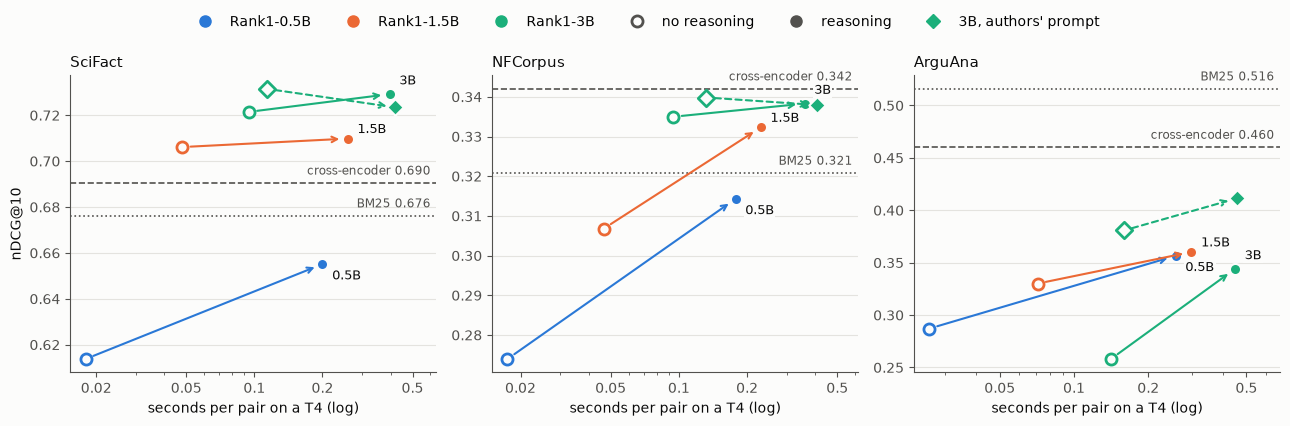

In [6]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#52514e",
                     "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb"})
COLOR = {"0.5b": "#2a78d6", "1.5b": "#eb6834", "3b": "#1baf7a"}
INK, MUTED = "#0b0b0b", "#52514e"

# cost against quality: hollow = no reasoning, filled = reasoning, one colour per model size
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, name in zip(axes, tb.DATASETS):
    for ref, style in (("T0", "--"), ("BM25", ":")):
        y = arr(ref, name).mean()
        ax.axhline(y, color=MUTED, lw=1.2, ls=style, zorder=1)
        ax.annotate(f"{'cross-encoder' if ref == 'T0' else 'BM25'} {y:.3f}", (1, y), xycoords=("axes fraction", "data"),
                    xytext=(-4, 4), textcoords="offset points", ha="right", va="bottom", fontsize=8.5, color=MUTED)
    for s in SIZES:
        x0, y0 = seconds[(f"T2-{s}", name)], arr(f"T2-{s}", name).mean()
        x1, y1 = seconds[(f"T1-{s}", name)], arr(f"T1-{s}", name).mean()
        ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", color=COLOR[s], lw=1.5, shrinkA=6, shrinkB=6))
        ax.scatter([x0], [y0], s=64, facecolors="#fcfcfb", edgecolors=COLOR[s], linewidths=2, zorder=3)
        ax.scatter([x1], [y1], s=64, color=COLOR[s], edgecolors="#fcfcfb", linewidths=1.5, zorder=3)
        dy = {"0.5b": -11, "1.5b": 4, "3b": 7}[s]
        ax.annotate(s.upper(), (x1, y1), xytext=(7, dy), textcoords="offset points", fontsize=9, color=INK,
                    bbox=dict(boxstyle="square,pad=0.1", fc="#fcfcfb", ec="none"), zorder=4)
    x0, y0 = seconds[("T4-3b", name)], arr("T4-3b", name).mean()
    x1, y1 = seconds[("T3-3b", name)], arr("T3-3b", name).mean()
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", color=COLOR["3b"], lw=1.5, ls=(0, (3, 2)), shrinkA=6, shrinkB=6))
    ax.scatter([x0], [y0], s=70, marker="D", facecolors="#fcfcfb", edgecolors=COLOR["3b"], linewidths=2, zorder=3)
    ax.scatter([x1], [y1], s=70, marker="D", color=COLOR["3b"], edgecolors="#fcfcfb", linewidths=1.5, zorder=3)
    ax.set_xscale("log")
    ax.set_xlim(right=ax.get_xlim()[1] * 1.3)
    ax.xaxis.set_major_locator(FixedLocator([0.02, 0.05, 0.1, 0.2, 0.5]))
    ax.xaxis.set_major_formatter(FormatStrFormatter("%g"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_title(NAMES[name], fontsize=11, color=INK, loc="left")
    ax.set_xlabel("seconds per pair on a T4 (log)")
    ax.grid(axis="y", color="#e4e3df", lw=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("nDCG@10")
handles = [plt.Line2D([], [], marker="o", ls="", markersize=8, color=COLOR[s], label=f"Rank1-{s.upper()}") for s in SIZES]
handles += [plt.Line2D([], [], marker="o", ls="", markersize=8, markerfacecolor="#fcfcfb", markeredgecolor=MUTED, mew=2, label="no reasoning"),
            plt.Line2D([], [], marker="o", ls="", markersize=8, color=MUTED, label="reasoning"),
            plt.Line2D([], [], marker="D", ls="", markersize=7, color=COLOR["3b"], label="3B, authors' prompt")]
fig.legend(handles=handles, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIG / "cost_quality.png", dpi=200)
plt.show()

| Dataset | Run | scores < 0.01 or > 0.99 | docs > 0.99 per query | queries with ≥ 2 docs > 0.99 | relevant judged true | non-relevant judged true |
|---|---|:-:|:-:|:-:|:-:|:-:|
| SciFact | Rank1-0.5B reasoning | 99% | 1.1 | 19% | 53% | 3% |
| SciFact | Rank1-1.5B reasoning | 99% | 1.0 | 17% | 54% | 3% |
| SciFact | Rank1-3B reasoning | 96% | 1.2 | 22% | 62% | 4% |
| SciFact | Rank1-0.5B no reasoning | 24% | 0.0 | 0% | 2% | 0% |
| SciFact | Rank1-1.5B no reasoning | 32% | 0.0 | 0% | 57% | 4% |
| SciFact | Rank1-3B no reasoning | 8% | 0.1 | 1% | 93% | 30% |
| SciFact | Rank1-3B reasoning, authors' prompt | 98% | 1.3 | 25% | 64% | 4% |
| SciFact | Rank1-3B no reasoning, authors' prompt | 9% | 0.1 | 0% | 83% | 16% |
| NFCorpus | Rank1-0.5B reasoning | 99% | 3.0 | 47% | 47% | 9% |
| NFCorpus | Rank1-1.5B reasoning | 98% | 4.7 | 63% | 71% | 15% |
| NFCorpus | Rank1-3B reasoning | 96% | 5.0 | 66% | 73% | 15% |
| NFCorpus | Rank1-0.5B no reasoning | 9% | 0.0 | 0% | 0% | 0% |
| NFCorpus | Ran

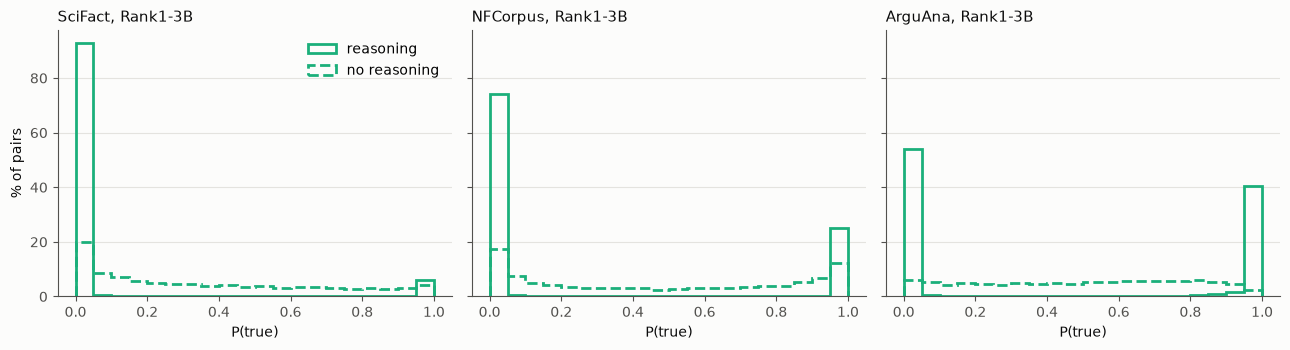

In [7]:
# polarization and how the top of the ranking looks
rows = ["| Dataset | Run | scores < 0.01 or > 0.99 | docs > 0.99 per query | queries with ≥ 2 docs > 0.99 | relevant judged true | non-relevant judged true |",
        "|---|---|:-:|:-:|:-:|:-:|:-:|"]
for name in tb.DATASETS:
    for tag in RANK1:
        recs = pairs[(tag, name)]
        sc = [r["score"] for r in recs.values()]
        by_q = {}
        for (q, d), r in recs.items():
            by_q.setdefault(q, []).append(r["score"])
        hi = [sum(x > 0.99 for x in v) for v in by_q.values()]
        rel = [r["score"] > 0.5 for (q, d), r in recs.items() if qrels[name][q].get(d, 0) > 0]
        non = [r["score"] > 0.5 for (q, d), r in recs.items() if qrels[name][q].get(d, 0) <= 0]
        rows.append(f"| {NAMES[name]} | {LABEL[tag]} | {np.mean([x < 0.01 or x > 0.99 for x in sc]):.0%} | {np.mean(hi):.1f} | "
                    f"{np.mean([h >= 2 for h in hi]):.0%} | {np.mean(rel):.0%} | {np.mean(non):.0%} |")
write("\n".join(rows), "polarization.md")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, name in zip(axes, tb.DATASETS):
    for tag, ls, lab in (("T1-3b", "-", "reasoning"), ("T2-3b", "--", "no reasoning")):
        sc = [r["score"] for r in pairs[(tag, name)].values()]
        w = np.full(len(sc), 100 / len(sc))
        ax.hist(sc, bins=bins, weights=w, histtype="step", lw=2, ls=ls, color=COLOR["3b"], label=lab)
    ax.set_title(f"{NAMES[name]}, Rank1-3B", fontsize=11, color=INK, loc="left")
    ax.set_xlabel("P(true)")
    ax.grid(axis="y", color="#e4e3df", lw=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("% of pairs")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "polarization.png", dpi=200)
plt.show()

In [8]:
def ranking(tag, name, q):
    return sorted(runs[(tag, name)][q], key=runs[(tag, name)][q].get, reverse=True)


def snippet(text, words=45):
    w = text.split()
    return " ".join(w[:words]) + (" …" if len(w) > words else "")


def last_sentences(text, n=2):
    s = [x.strip() for x in text.replace("\n", " ").split(".") if x.strip()]
    return ". ".join(s[-n:]) + "."


def cases(name, a, b, k, worst):
    # queries where run a loses (worst) or gains most against run b
    diff = {q: ndcg[(a, name)][q] - ndcg[(b, name)][q] for q in queries[name]}
    out = [f"## {NAMES[name]}: {'losses' if worst else 'gains'} of {LABEL[a]} against {LABEL[b]}", ""]
    for q in sorted(diff, key=diff.get, reverse=not worst)[:k]:
        ra, rb = ranking(a, name, q), ranking(b, name, q)
        rel = [d for d, g in qrels[name][q].items() if g > 0]
        top = ra[0]
        rec = pairs[(a, name)].get((q, top), {})
        out += [f"### query {q}: nDCG@10 {ndcg[(a, name)][q]:.2f} vs {ndcg[(b, name)][q]:.2f}", "",
                f"**Query.** {snippet(queries[name][q], 60)}", ""]
        for d in rel[:2]:
            pos_a = ra.index(d) + 1 if d in ra else None
            pos_b = rb.index(d) + 1 if d in rb else None
            s = pairs[(a, name)].get((q, d), {}).get("score")
            out += [f"**Relevant {d}** (rank {pos_a} vs {pos_b}" + (f", P(true) {s:.3f})" if s is not None else ")") +
                    f". {snippet(texts[name][d])}", ""]
        out += [f"**Rank 1 for {LABEL[a]}: {top}** (P(true) {rec.get('score', float('nan')):.3f}, "
                f"{'relevant' if top in rel else 'not relevant'}). {snippet(texts[name][top])}", ""]
        if rec.get("text"):
            out += [f"> {last_sentences(rec['text'])}", ""]
    return "\n".join(out)


report = "\n\n".join([cases("arguana", "T1-3b", "T0", 5, True), cases("arguana", "T3-3b", "T1-3b", 3, False),
                       cases("scifact", "T1-3b", "T0", 5, False)])
(TAB / "error_analysis.md").write_text(report + "\n")
print(report[:6000])

## ArguAna: losses of Rank1-3B reasoning against T0 cross-encoder

### query test-health-hdond-pro04a: nDCG@10 0.00 vs 1.00

**Query.** People ought to donate their organs anyway Organ donation, in all its forms, saves lives. More to the point, it saves lives with almost no loss to the donor. One obviously has no material need for one’s organs after death, and thus it does not meaningfully inhibit bodily integrity to incentivize people to give up their organs at this time. …

**Relevant test-health-hdond-pro04b** (rank 12 vs 1, P(true) 0.918). healthcare deny organs non donors Even granting the premise that people ought to donate their organs anyway, the role of the state is not to coerce people to do things they ought to do. People ought to be polite to strangers, exercise regularly, and make …

**Rank 1 for Rank1-3B reasoning: test-health-hpehwadvoee-con04b** (P(true) 1.000, not relevant). healthcare philosophy ethics house would allow donations vital organs even expense If the purpo

In [9]:
# reasoning that never ends: pairs that hit the 2,048-token cap
rows = ["| Run | " + " | ".join(NAMES.values()) + " |", "|---|" + ":-:|" * 3]
for tag in [f"T1-{s}" for s in SIZES] + ["T3-3b"]:
    cells_ = []
    for name in tb.DATASETS:
        recs = pairs[(tag, name)].values()
        cells_.append(f"{sum(r['capped'] for r in recs)} ({np.mean([r['capped'] for r in recs]):.1%})")
    rows.append(f"| {LABEL[tag]} | " + " | ".join(cells_) + " |")
write("\n".join(rows), "token_cap.md")
loop = next(r for r in pairs[("T1-0.5b", "arguana")].values() if r["capped"])
print("\nexample:", loop["text"][:400].replace("\n", " "), "…", loop["text"][-150:].replace("\n", " "))

| Run | SciFact | NFCorpus | ArguAna |
|---|:-:|:-:|:-:|
| Rank1-0.5B reasoning | 5 (0.1%) | 6 (0.1%) | 615 (2.2%) |
| Rank1-1.5B reasoning | 2 (0.0%) | 1 (0.0%) | 39 (0.1%) |
| Rank1-3B reasoning | 3 (0.1%) | 0 (0.0%) | 14 (0.0%) |
| Rank1-3B reasoning, authors' prompt | 2 (0.0%) | 1 (0.0%) | 31 (0.1%) |

example:  Okay, let's tackle this question. The user wants to know if the given passage is relevant to the query "It is immoral to kill animals as evolved human beings it is our moral duty to inflict as little pain as possible for our survival. So if we do not need to inflict pain to animals in order to survive, we should not do it. Farm animals such as chickens, pigs, sheep, and cows are sentient living b … 1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1] [1]


## BRIGHT: dataset version check

TheoremQA-theorems differs between BRIGHT revisions. This cell is self-contained (it only needs `datasets` and `huggingface_hub`) and compares the first stage of the paper (Table 1: 20.2) across revisions and with the authors' run file.

In [1]:
import os, json, math
os.environ.update(HF_HUB_DISABLE_PROGRESS_BARS="1", HF_DATASETS_DISABLE_PROGRESS_BARS="1",
                  HF_HUB_VERBOSITY="error", DATASETS_VERBOSITY="error")
from datasets import load_dataset
from huggingface_hub import hf_hub_download

VERSIONS = {"pinned by the authors' code (our runs)": "0dc152a5d69327d457c0390c692baf8e5808424b",
            "revision 3066d29": "3066d29c9651a576c8aba4832d249807b181ecae",
            "latest": "main"}
run = json.load(open(hf_hub_download("jhu-clsp/rank1-run-files", "theoremqa_theorems_bm25_long_False/score.json",
                                     repo_type="dataset")))


def ndcg10(ranked, rel):
    dcg = sum(1 / math.log2(i + 2) for i, d in enumerate(ranked[:10]) if d in rel)
    idcg = sum(1 / math.log2(i + 2) for i in range(min(len(rel), 10)))
    return dcg / idcg if idcg else 0.0


examples = {}
for label, rev in VERSIONS.items():
    try:
        ex = load_dataset("xlangai/BRIGHT", "examples", split="theoremqa_theorems", revision=rev)
        examples[label] = {str(e["id"]): (e["query"], set(map(str, e["gold_ids"]))) for e in ex}
    except Exception as err:
        print(f"{label}: not available ({type(err).__name__})")

ours = examples[next(iter(examples))]
print(f"first-stage run file: {len(run)} queries; paper, Table 1: 20.2")
for label, ex in examples.items():
    qs = [q for q in ex if q in run]
    nd = [ndcg10(sorted(run[q], key=run[q].get, reverse=True), ex[q][1]) for q in qs]
    extra = [q for q in ex if q not in ours]
    changed = [q for q in ex if q in ours and ex[q] != ours[q]]
    print(f"{label}: {len(ex)} queries ({len(qs)} in the run file), first-stage nDCG@10 {100 * sum(nd) / max(1, len(nd)):.1f}"
          f" | not in our runs: {len(extra)} {extra}, changed text or labels: {len(changed)}")

# queries of the authors' run file that no revision contains: if they count as 0, the mean over all of them is
missing = [q for q in run if all(q not in ex for ex in examples.values())]
nd = [ndcg10(sorted(run[q], key=run[q].get, reverse=True), ours[q][1]) for q in ours if q in run]
print(f"run-file queries in no revision: {missing}; first stage over {len(nd) + len(missing)} queries with these at 0: "
      f"{100 * sum(nd) / (len(nd) + len(missing)):.1f}")

first-stage run file: 78 queries; paper, Table 1: 20.2
pinned by the authors' code (our runs): 76 queries (76 in the run file), first-stage nDCG@10 20.8 | not in our runs: 0 [], changed text or labels: 0
revision 3066d29: 76 queries (76 in the run file), first-stage nDCG@10 20.8 | not in our runs: 0 [], changed text or labels: 0
latest: 76 queries (76 in the run file), first-stage nDCG@10 20.8 | not in our runs: 0 [], changed text or labels: 0
run-file queries in no revision: ['TheoremQA_xueguangma/fundamental_theorem_of_calculus.json', 'TheoremQA_maxku/signalprocessing10-nyquist.json']; first stage over 78 queries with these at 0: 20.2
